# Compare ESP streamflow evaluations

Compare precomputed Ensemble Streamflow Prediction (ESP) hindcasts. Each entry points at an evaluation directory written by `snowda.workflows.evaluate_esp_streamflow`, or at the `metrics.json` in that directory. This notebook reads the sibling `metrics.nc`. That file holds the lead-time CRPS, peak and volume scores, bootstrap intervals, rank histograms, and peak-over-horizon event probabilities used below.

Scores are not recomputed. Hydrograph envelopes and per-forecast plots load the ESP traces from the matching hindcast directories. The other figures read the saved metrics.

The stored diagnostics are:

- Daily CRPS and CRPSS versus observational streamflow climatology on the same calendar day
- Peak-flow CRPS and CRPSS, one score per forecast for the maximum discharge over the horizon
- Water-volume CRPS and CRPSS for the total volume over the paired days
- Block-bootstrap intervals on the initiation-month means, when that evaluation saved them
- Peak-over-horizon Brier score, Brier skill score, reliability, and ROC at the saved return-period thresholds
- Rank histogram of the observation within the ensemble

A line or bar is drawn only for a score that evaluation saved. Shading on the lead-time curves is the saved block-bootstrap interval of the mean score at that lead.


In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
from matplotlib.lines import Line2D

from snowda.adapters.scores import reliability_diagram, roc_diagram

## Evaluations

Edit the labels and paths together. `EVALUATIONS` points at a saved `metrics.json` (or its directory or `metrics.nc`). `HINDCASTS` points at the ESP run directory that produced that score file. The labels have to match.

`PLOT_START` and `PLOT_END` set the hydrograph window. The envelope figure draws every forecast that falls in the window. The per-forecast figures are one initialization at a time, for the same window.

The paths below are the Ross River open-loop hindcast and the SWE particle-filter hindcast. The assimilation run does not include the 2006-04-01 and 2017-03-01 issue dates.


In [12]:
EVALUATIONS = {
    "No DA": Path(
        "/Users/dcasson/GitHub/snowda/outputs/"
        "ross_esp_streamflow_20_year_eval_no_da/20261027T152946Z/metrics.json"
    ),
    "DA": Path(
        "/Users/dcasson/GitHub/snowda/outputs/"
        "ross_esp_streamflow_20_year_eval_da/20261027T155729Z/metrics.json"
    )
}


def resolve_metrics_nc(path: Path) -> Path:
    path = Path(path)
    if path.is_dir():
        nc_path = path / "metrics.nc"
    elif path.name == "metrics.json":
        nc_path = path.with_name("metrics.nc")
    elif path.suffix == ".nc":
        nc_path = path
    else:
        raise ValueError(
            "Expected an evaluation directory, metrics.json, or metrics.nc: "
            f"{path}"
        )
    if not nc_path.is_file():
        raise FileNotFoundError(
            f"{nc_path} is missing. This notebook reads saved metrics and does not recompute scores."
        )
    return nc_path


def load_evaluations(paths: dict[str, Path]) -> dict[str, xr.Dataset]:
    if len(paths) < 2:
        raise ValueError("Add at least two evaluations to compare.")
    loaded: dict[str, xr.Dataset] = {}
    for label, path in paths.items():
        nc_path = resolve_metrics_nc(path)
        dataset = xr.load_dataset(nc_path)
        dataset.attrs["label"] = label
        dataset.attrs["metrics_nc"] = str(nc_path)
        loaded[label] = dataset
        print(f"{label}: {nc_path}")
    return loaded


evaluations = load_evaluations(EVALUATIONS)
RUN_COLORS = {
    label: plt.get_cmap("tab10")(index) for index, label in enumerate(evaluations)
}

HINDCASTS = {
    "No DA": Path("/Users/dcasson/GitHub/snowda/outputs/ross_summa_esp/20261027T124504Z"),
    "DA": Path("/Users/dcasson/GitHub/snowda/outputs/ross_summa_esp/20261027T144509Z"),
}
OBS_CSV = Path("/Users/dcasson/GitHub/snowda/data/ross_daily_discharge.csv")
THRESHOLDS_CSV = Path(
    "/Users/dcasson/Data/snowda/summa/ross_lumped/thresholds/ross_thresholds.csv"
)
PLOT_START = "1990-01-01"
PLOT_END = "2020-01-01"
RESAMPLE = "1D"
VARIABLE = "IRFroutedRunoff"
SEG = 0


No DA: /Users/dcasson/GitHub/snowda/outputs/ross_esp_streamflow_20_year_eval_no_da/20261027T152946Z/metrics.nc
DA: /Users/dcasson/GitHub/snowda/outputs/ross_esp_streamflow_20_year_eval_da/20261027T155729Z/metrics.nc


## Reshape saved scores

These helpers only index the loaded datasets. Reliability and ROC diagrams bin the saved event probabilities; they do not rescore the hindcasts.

In [13]:
FLOW_UNIT = "m3 s-1"
VOLUME_UNIT = "m3"
MEAN_FIELDS = (
    "n_forecasts",
    "n_members",
    "n_pairs",
    "crps_mean",
    "crps_mean_ci_lower",
    "crps_mean_ci_upper",
    "crpss_mean",
    "crpss_mean_ci_lower",
    "crpss_mean_ci_upper",
    "peak_crps_mean",
    "peak_crps_mean_ci_lower",
    "peak_crps_mean_ci_upper",
    "peak_crpss_mean",
    "peak_crpss_mean_ci_lower",
    "peak_crpss_mean_ci_upper",
    "volume_crps_mean",
    "volume_crps_mean_ci_lower",
    "volume_crps_mean_ci_upper",
    "volume_crpss_mean",
    "volume_crpss_mean_ci_lower",
    "volume_crpss_mean_ci_upper",
)
METHOD_FIELDS = (
    "crps_method",
    "fair_brier",
    "exclude_verification_year",
    "event_probability_threshold",
    "binary_event",
    "return_periods",
    "skill_reference",
    "peak_definition",
    "volume_definition",
    "bootstrap_iterations",
    "bootstrap_block_size",
    "bootstrap_ci_level",
)


def init_months(dataset: xr.Dataset) -> list[str]:
    if "init_month" not in dataset.coords and "init_month" not in dataset.dims:
        return []
    return [str(month) for month in np.atleast_1d(dataset["init_month"].values)]


def return_periods(dataset: xr.Dataset) -> list[float]:
    if "return_period" not in dataset.coords and "return_period" not in dataset.dims:
        return []
    return [float(period) for period in np.atleast_1d(dataset["return_period"].values)]


def ordered_months(runs: dict[str, xr.Dataset]) -> list[str]:
    months: list[str] = []
    for dataset in runs.values():
        for month in init_months(dataset):
            if month not in months:
                months.append(month)
    return months


def ordered_periods(runs: dict[str, xr.Dataset]) -> list[float]:
    periods: list[float] = []
    for dataset in runs.values():
        for period in return_periods(dataset):
            if not any(np.isclose(period, saved) for saved in periods):
                periods.append(period)
    return periods


def period_text(period: float) -> str:
    if float(period).is_integer():
        return str(int(period))
    return str(period)


def _coord_value(dataset: xr.Dataset, name: str, wanted: float):
    values = np.asarray(dataset[name].values)
    numeric = np.asarray(values, dtype=float)
    matches = np.where(np.isclose(numeric, float(wanted)))[0]
    if matches.size == 0:
        return None
    return values[int(matches[0])]


def scalar(dataset: xr.Dataset, name: str, month: str) -> float:
    if name not in dataset or month not in init_months(dataset):
        return np.nan
    values = np.asarray(dataset[name].sel(init_month=month).values, dtype=float)
    if values.shape != ():
        return np.nan
    return float(values)


def period_scalar(dataset: xr.Dataset, name: str, month: str, period: float) -> float:
    if name not in dataset or month not in init_months(dataset):
        return np.nan
    if "return_period" not in dataset[name].dims:
        return np.nan
    saved = _coord_value(dataset, "return_period", period)
    if saved is None:
        return np.nan
    values = np.asarray(
        dataset[name].sel(init_month=month, return_period=saved).values,
        dtype=float,
    )
    if values.shape != ():
        return np.nan
    return float(values)


def attr_text(dataset: xr.Dataset, name: str) -> str:
    if name not in dataset.attrs:
        return ""
    return str(dataset.attrs[name])


def unit_of(runs: dict[str, xr.Dataset], variable: str, default: str) -> str:
    for dataset in runs.values():
        if variable in dataset and dataset[variable].attrs.get("units"):
            return str(dataset[variable].attrs["units"])
    return default


def metadata_table(runs: dict[str, xr.Dataset]) -> pd.DataFrame:
    rows = []
    for label, dataset in runs.items():
        members = [
            int(scalar(dataset, "n_members", month))
            for month in init_months(dataset)
            if np.isfinite(scalar(dataset, "n_members", month))
        ]
        member_text = ""
        if members:
            member_text = (
                str(members[0])
                if len(set(members)) == 1
                else ", ".join(str(count) for count in members)
            )
        rows.append(
            {
                "run": label,
                "n_forecasts": attr_text(dataset, "n_forecasts"),
                "n_pairs": attr_text(dataset, "n_pairs"),
                "n_members": member_text,
                "init_months": ", ".join(init_months(dataset)),
                "return_periods": ", ".join(
                    period_text(period) for period in return_periods(dataset)
                ),
                "crps_method": attr_text(dataset, "crps_method"),
                "fair_brier": attr_text(dataset, "fair_brier"),
                "exclude_verification_year": attr_text(
                    dataset, "exclude_verification_year"
                ),
                "event_probability_threshold": attr_text(
                    dataset, "event_probability_threshold"
                ),
                "binary_event": attr_text(dataset, "binary_event"),
                "score_peak": attr_text(dataset, "score_peak"),
                "score_volume": attr_text(dataset, "score_volume"),
                "bootstrap_iterations": attr_text(dataset, "bootstrap_iterations"),
                "bootstrap_block_size": attr_text(dataset, "bootstrap_block_size"),
                "bootstrap_ci_level": attr_text(dataset, "bootstrap_ci_level"),
            }
        )
    return pd.DataFrame(rows).set_index("run")


def report_method_differences(runs: dict[str, xr.Dataset]) -> None:
    for field in METHOD_FIELDS:
        values = {label: attr_text(dataset, field) for label, dataset in runs.items()}
        present = {label: value for label, value in values.items() if value}
        differs = len(set(present.values())) > 1 or len(present) != len(runs)
        if differs:
            print(f"{field} is not shared: {values}")


def summary_table(runs: dict[str, xr.Dataset]) -> pd.DataFrame:
    periods = ordered_periods(runs)
    rows = []
    for label, dataset in runs.items():
        for month in init_months(dataset):
            row = {"run": label, "init_month": month}
            for name in MEAN_FIELDS:
                row[name] = scalar(dataset, name, month)
            for period in periods:
                key = period_text(period)
                for name in ("bs", "bss", "pod", "far", "yp"):
                    row[f"{name}_{key}"] = period_scalar(dataset, name, month, period)
            rows.append(row)
    return pd.DataFrame(rows).set_index(["run", "init_month"])


def plot_score_by_lead(runs: dict[str, xr.Dataset], *, skill: bool) -> plt.Figure:
    variable = "crpss" if skill else "crps"
    if skill:
        ylabel = "CRPSS"
        title = "CRPSS vs lead"
    else:
        ylabel = f"CRPS ({unit_of(runs, 'peak_crps', FLOW_UNIT)})"
        title = "CRPS vs lead"
    months = ordered_months(runs)
    fig, axes = plt.subplots(
        len(months),
        1,
        figsize=(10, 3.1 * len(months)),
        sharex=True,
        squeeze=False,
    )
    for ax, month in zip(axes.ravel(), months):
        for label, dataset in runs.items():
            if variable not in dataset or month not in init_months(dataset):
                continue
            row = dataset[variable].sel(init_month=month)
            lead = np.asarray(row["lead"].values, dtype=float)
            values = np.asarray(row.values, dtype=float)
            (line,) = ax.plot(
                lead,
                values,
                color=RUN_COLORS[label],
                linewidth=1.6,
                label=label,
            )
            lower_name = f"{variable}_ci_lower"
            upper_name = f"{variable}_ci_upper"
            if lower_name in dataset and upper_name in dataset:
                lower = np.asarray(
                    dataset[lower_name].sel(init_month=month).values, dtype=float
                )
                upper = np.asarray(
                    dataset[upper_name].sel(init_month=month).values, dtype=float
                )
                ax.fill_between(
                    lead,
                    lower,
                    upper,
                    color=line.get_color(),
                    alpha=0.18,
                    linewidth=0,
                )
        ax.set_title(f"Init {month}")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.25)
        if skill:
            ax.axhline(0.0, color="0.4", linewidth=0.8, linestyle="--")
    axes.ravel()[-1].set_xlabel("Lead (days)")
    axes.ravel()[0].legend(loc="best")
    fig.suptitle(title, y=1.01)
    fig.tight_layout()
    return fig


def plot_month_means(runs: dict[str, xr.Dataset], specs: list[tuple]) -> plt.Figure:
    """Grouped bars of initiation-month means.

    ``specs`` entries are ``(variable, ylabel, title, draw_zero)``. Error bars
    are the saved bootstrap interval when both bounds are finite.
    """
    months = ordered_months(runs)
    labels = list(runs)
    fig, axes = plt.subplots(
        1,
        len(specs),
        figsize=(4.6 * len(specs), 4.3),
        squeeze=False,
        layout="constrained",
    )
    x = np.arange(len(months))
    width = 0.8 / max(len(labels), 1)
    for ax, (name, ylabel, title, draw_zero) in zip(axes.ravel(), specs):
        for index, label in enumerate(labels):
            dataset = runs[label]
            center = np.array([scalar(dataset, name, month) for month in months])
            if not np.any(np.isfinite(center)):
                continue
            lower = np.array(
                [scalar(dataset, f"{name}_ci_lower", month) for month in months]
            )
            upper = np.array(
                [scalar(dataset, f"{name}_ci_upper", month) for month in months]
            )
            offset = x + (index - (len(labels) - 1) / 2) * width
            ax.bar(
                offset,
                center,
                width=width,
                color=RUN_COLORS[label],
                label=label,
                zorder=2,
            )
            finite = (
                np.isfinite(center) & np.isfinite(lower) & np.isfinite(upper)
            )
            if np.any(finite):
                yerr = np.vstack(
                    [
                        np.maximum(center - lower, 0.0),
                        np.maximum(upper - center, 0.0),
                    ]
                )
                ax.errorbar(
                    offset[finite],
                    center[finite],
                    yerr=yerr[:, finite],
                    fmt="none",
                    ecolor="0.15",
                    elinewidth=1.0,
                    capsize=3,
                    zorder=3,
                )
        ax.set_xticks(x)
        ax.set_xticklabels(months)
        ax.set_xlabel("Init month")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(True, axis="y", alpha=0.25)
        ax.set_axisbelow(True)
        if draw_zero:
            ax.axhline(0.0, color="0.4", linewidth=0.8, linestyle="--", zorder=1)
    handles, labels = axes.ravel()[0].get_legend_handles_labels()
    if handles:
        fig.legend(
            handles,
            labels,
            loc="outside upper center",
            ncol=len(labels),
            frameon=False,
        )
    return fig


def _finite_init_series(dataset: xr.Dataset, name: str, month: str):
    if name not in dataset or month not in init_months(dataset):
        return None
    row = dataset[name].sel(init_month=month)
    if "init_time" not in row.coords:
        return None
    times = pd.to_datetime(np.atleast_1d(row["init_time"].values))
    values = np.atleast_1d(np.asarray(row.values, dtype=float))
    finite = np.isfinite(values)
    if not np.any(finite):
        return None
    order = np.argsort(times[finite])
    return pd.DatetimeIndex(times[finite][order]), values[finite][order]


def plot_horizon_scores(
    runs: dict[str, xr.Dataset],
    crps_name: str,
    crpss_name: str,
    crps_label: str,
    crpss_label: str,
) -> plt.Figure | None:
    available = [
        label
        for label, dataset in runs.items()
        if crps_name in dataset and crpss_name in dataset
    ]
    if not available:
        print(f"No saved {crps_name}; skipping that figure.")
        return None
    months = ordered_months(runs)
    fig, axes = plt.subplots(
        2,
        len(months),
        figsize=(4.4 * len(months), 7.0),
        sharex="col",
        squeeze=False,
    )
    for column, month in enumerate(months):
        for label in available:
            dataset = runs[label]
            crps = _finite_init_series(dataset, crps_name, month)
            crpss = _finite_init_series(dataset, crpss_name, month)
            if crps is not None:
                axes[0, column].plot(
                    crps[0],
                    crps[1],
                    color=RUN_COLORS[label],
                    marker="o",
                    markersize=4,
                    linewidth=1.4,
                )
            if crpss is not None:
                axes[1, column].plot(
                    crpss[0],
                    crpss[1],
                    color=RUN_COLORS[label],
                    marker="o",
                    markersize=4,
                    linewidth=1.4,
                )
        axes[0, column].set_title(f"Init {month}")
        axes[0, column].set_ylabel(crps_label)
        axes[1, column].set_ylabel(crpss_label)
        axes[1, column].set_xlabel("Initialization time")
        axes[1, column].axhline(0.0, color="0.4", linewidth=0.8, linestyle="--")
        for row in range(2):
            axes[row, column].grid(True, alpha=0.25)
    handles = [
        Line2D(
            [0],
            [0],
            color=RUN_COLORS[label],
            marker="o",
            linewidth=1.4,
            label=label,
        )
        for label in available
    ]
    axes[0, 0].legend(handles=handles, loc="best")
    fig.autofmt_xdate()
    fig.tight_layout()
    return fig


def _threshold_tick_labels(runs, periods, month) -> list[str]:
    labels = []
    for period in periods:
        values = [
            period_scalar(dataset, "yp", month, period)
            for dataset in runs.values()
        ]
        finite = [value for value in values if np.isfinite(value)]
        text = f"{period_text(period)} yr"
        if finite and np.allclose(finite, finite[0]):
            text = f"{text}\n({finite[0]:.0f})"
        labels.append(text)
    return labels


def plot_threshold_bars(
    runs: dict[str, xr.Dataset],
    names: tuple[str, ...],
    titles: tuple[str, ...],
) -> plt.Figure | None:
    if not any(name in dataset for dataset in runs.values() for name in names):
        print(f"No saved {', '.join(names)}; skipping that figure.")
        return None
    months = ordered_months(runs)
    periods = ordered_periods(runs)
    labels = list(runs)
    fig, axes = plt.subplots(
        len(names),
        len(months),
        figsize=(4.3 * len(months), 3.7 * len(names)),
        sharex=True,
        squeeze=False,
        layout="constrained",
    )
    x = np.arange(len(periods))
    width = 0.8 / max(len(labels), 1)
    for row, (name, title) in enumerate(zip(names, titles)):
        for column, month in enumerate(months):
            ax = axes[row, column]
            for index, label in enumerate(labels):
                values = np.array(
                    [
                        period_scalar(runs[label], name, month, period)
                        for period in periods
                    ]
                )
                if not np.any(np.isfinite(values)):
                    continue
                ax.bar(
                    x + (index - (len(labels) - 1) / 2) * width,
                    values,
                    width=width,
                    color=RUN_COLORS[label],
                    label=label,
                )
            if name == "bss":
                ax.axhline(0.0, color="0.4", linewidth=0.8, linestyle="--")
            ax.set_title(f"{title}, init {month}")
            ax.grid(True, axis="y", alpha=0.25)
            ax.set_axisbelow(True)
            ax.set_xticks(x)
            ax.set_xticklabels(_threshold_tick_labels(runs, periods, month))
        axes[row, 0].set_ylabel(title)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    if handles:
        fig.legend(
            handles,
            labels,
            loc="outside upper center",
            ncol=len(labels),
            frameon=False,
        )
    return fig


def _select_diagram(diagram: xr.Dataset, period: float, month: str):
    if month not in init_months(diagram):
        return None
    selected = diagram.sel(init_month=month)
    if "return_period" in selected.dims or "return_period" in selected.coords:
        saved = _coord_value(diagram, "return_period", period)
        if saved is None:
            return None
        selected = selected.sel(return_period=saved)
    return selected


def _diagram_grid(diagrams: dict[str, xr.Dataset], panel_size: float):
    months = ordered_months(diagrams)
    periods = ordered_periods(diagrams)
    fig, axes = plt.subplots(
        len(months),
        len(periods),
        figsize=(panel_size * len(periods), panel_size * len(months)),
        sharex=True,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    return months, periods, fig, axes


def plot_reliability(diagrams: dict[str, xr.Dataset]) -> plt.Figure:
    """One panel per initiation month and return period, one curve per run."""
    months, periods, fig, axes = _diagram_grid(diagrams, 3.5)
    labeled = False
    for row, month in enumerate(months):
        for column, period in enumerate(periods):
            ax = axes[row, column]
            ax.plot([0.0, 1.0], [0.0, 1.0], color="0.45", linestyle="--", linewidth=0.8)
            prepared = []
            for label, diagram in diagrams.items():
                series = _select_diagram(diagram, period, month)
                if series is None or "mean_forecast" not in series:
                    continue
                forecast = np.asarray(series["mean_forecast"].values, dtype=float).ravel()
                frequency = np.asarray(
                    series["observed_frequency"].values, dtype=float
                ).ravel()
                counts = np.asarray(series["count"].values, dtype=float).ravel()
                keep = np.isfinite(forecast) & np.isfinite(frequency) & (counts > 0)
                if not np.any(keep):
                    continue
                order = np.argsort(forecast[keep])
                prepared.append(
                    (
                        label,
                        forecast[keep][order],
                        frequency[keep][order],
                        counts[keep][order],
                        series,
                    )
                )
            max_count = max((float(np.max(item[3])) for item in prepared), default=1.0)
            for label, forecast, frequency, counts, series in prepared:
                color = RUN_COLORS[label]
                ax.plot(
                    forecast,
                    frequency,
                    color=color,
                    linewidth=1.4,
                    label=label if not labeled else None,
                )
                ax.scatter(
                    forecast,
                    frequency,
                    s=18.0 + 90.0 * (counts / max_count),
                    color=color,
                    zorder=3,
                )
                if "event_frequency" in series:
                    rate = float(np.asarray(series["event_frequency"].values, dtype=float))
                    if np.isfinite(rate):
                        ax.axhline(
                            rate, color=color, linestyle=":", linewidth=0.8, alpha=0.7
                        )
            labeled = labeled or bool(prepared)
            ax.set_xlim(0.0, 1.0)
            ax.set_ylim(0.0, 1.0)
            ax.set_box_aspect(1)
            ax.set_title(f"{month}, {period_text(period)}-year", fontsize=10)
            ax.grid(True, alpha=0.25)
            if row == len(months) - 1:
                ax.set_xlabel("Forecast probability")
            if column == 0:
                ax.set_ylabel("Observed frequency")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    if handles:
        fig.legend(
            handles,
            labels,
            loc="outside upper center",
            ncol=len(labels),
            frameon=False,
        )
    return fig


def plot_roc(diagrams: dict[str, xr.Dataset]) -> plt.Figure:
    """One panel per initiation month and return period, one curve per run."""
    months, periods, fig, axes = _diagram_grid(diagrams, 3.6)
    for row, month in enumerate(months):
        for column, period in enumerate(periods):
            ax = axes[row, column]
            ax.plot([0.0, 1.0], [0.0, 1.0], color="0.45", linestyle="--", linewidth=0.8)
            for label, diagram in diagrams.items():
                series = _select_diagram(diagram, period, month)
                if series is None or "POD" not in series:
                    continue
                pofd = np.asarray(series["POFD"].values, dtype=float).ravel()
                pod = np.asarray(series["POD"].values, dtype=float).ravel()
                keep = np.isfinite(pofd) & np.isfinite(pod)
                if not np.any(keep):
                    continue
                text = label
                if "AUC" in series:
                    auc = float(np.asarray(series["AUC"].values, dtype=float))
                    if np.isfinite(auc):
                        text = f"{label} ({auc:.2f})"
                ax.plot(
                    pofd[keep],
                    pod[keep],
                    color=RUN_COLORS[label],
                    linewidth=1.4,
                    label=text,
                )
            ax.set_xlim(0.0, 1.0)
            ax.set_ylim(0.0, 1.0)
            ax.set_box_aspect(1)
            ax.set_title(f"{month}, {period_text(period)}-year", fontsize=10)
            ax.grid(True, alpha=0.25)
            ax.legend(loc="lower right", fontsize=6.5)
            if row == len(months) - 1:
                ax.set_xlabel("False alarm rate")
            if column == 0:
                ax.set_ylabel("Probability of detection")
    return fig


def plot_rank_histograms(runs: dict[str, xr.Dataset]) -> plt.Figure | None:
    available = [label for label, dataset in runs.items() if "rank_histogram" in dataset]
    if not available:
        print("No saved rank_histogram; skipping that figure.")
        return None
    months = ordered_months(runs)
    fig, axes = plt.subplots(
        1,
        len(months),
        figsize=(4.8 * len(months), 4.1),
        sharey=True,
        squeeze=False,
    )
    width = 0.8 / max(len(available), 1)
    for ax, month in zip(axes.ravel(), months):
        for index, label in enumerate(available):
            dataset = runs[label]
            if month not in init_months(dataset):
                continue
            row = dataset["rank_histogram"].sel(init_month=month)
            ranks = np.asarray(row["rank"].values, dtype=float)
            frequency = np.asarray(row.values, dtype=float)
            keep = np.isfinite(frequency)
            offset = (index - (len(available) - 1) / 2) * width
            ax.bar(
                ranks[keep] + offset,
                frequency[keep],
                width=width * 0.92,
                color=RUN_COLORS[label],
                label=label,
            )
            n_bins = int(np.sum(keep))
            if n_bins:
                ax.axhline(
                    1.0 / n_bins,
                    color=RUN_COLORS[label],
                    linestyle="--",
                    linewidth=0.9,
                )
        ax.set_title(f"Init {month}")
        ax.set_xlabel("Observation rank")
        ax.set_ylabel("Frequency")
        ax.set_ylim(bottom=0.0)
        ax.grid(True, axis="y", alpha=0.25)
        ax.set_axisbelow(True)
    axes.ravel()[0].legend(loc="best")
    fig.tight_layout()
    return fig

## Setup and summary

The metadata row is what each evaluation recorded about its sample and scoring choices. The summary table is one row per run and initiation month. Missing entries are scores that file did not store. Bootstrap bounds are the saved `ci_lower` and `ci_upper` on the month-mean scores.

In [14]:
metadata = metadata_table(evaluations)
display(metadata.T)
report_method_differences(evaluations)

summary = summary_table(evaluations)
summary

run,No DA,DA
n_forecasts,60,58
n_pairs,7340,7065
n_members,20,20
init_months,"03-01, 04-01, 05-01","03-01, 04-01, 05-01"
return_periods,"2, 5, 10, 20","2, 5, 10, 20"
crps_method,fair,fair
fair_brier,True,True
exclude_verification_year,True,True
event_probability_threshold,0.5,0.5
binary_event,peak-over-horizon,peak-over-horizon


n_forecasts  n_members  n_pairs  crps_mean  \
run   init_month                                               
No DA 03-01              20.0       20.0   3060.0  40.564338   
      04-01              20.0       20.0   2440.0  51.654446   
      05-01              20.0       20.0   1840.0  64.284794   
DA    03-01              19.0       20.0   2907.0  27.917883   
      04-01              19.0       20.0   2318.0  33.838106   
      05-01              20.0       20.0   1840.0  41.136492   

                  crps_mean_ci_lower  crps_mean_ci_upper  crpss_mean  \
run   init_month                                                       
No DA 03-01                33.307400           47.505730   -2.320650   
      04-01                41.576721           64.417361   -1.880837   
      05-01                50.898702           78.521328   -1.048530   
DA    03-01                23.448353           32.278254   -1.796641   
      04-01                29.298185           39.037985   -1.135862   
      05-01                34.637146           47.549807   -0.149627   

                  crpss_mean_ci_lower  crpss_mean_ci_upper  peak_crps_mean  \
run   init_month                                                             
No DA 03-01                 -2.955039            -1.801907      146.041405   
      04-01                 -2.622632            -1.271167      155.708985   
      05-01                 -1.727297            -0.493335      150.939248   
DA    03-01                 -2.285479            -1.359245       66.005395   
      04-01                 -1.475957            -0.886858       56.954334   
      05-01                 -0.355520             0.016880       53.115710   

                  ...     bs_10    bss_10  pod_10  far_10       yp_10  \
run   init_month  ...                                                   
No DA 03-01       ...  0.304737 -4.787084     0.0     1.0  579.016146   
      04-01       ...  0.301579 -4.727114     0.0     1.0  579.016146   
      05-01       ...  0.297105 -4.616290     0.0     1.0  579.016146   
DA    03-01       ...  0.137396 -1.508153     0.0     1.0  579.016146   
      04-01       ...  0.121053 -1.209804     0.0     1.0  579.016146   
      05-01       ...  0.091053 -0.721201     0.0     1.0  579.016146   

                     bs_20    bss_20  pod_20  far_20     yp_20  
run   init_month                                                
No DA 03-01       0.203421 -3.136159     0.0     1.0  646.1254  
      04-01       0.240526 -3.890620     0.0     1.0  646.1254  
      05-01       0.240000 -3.874822     0.0     1.0  646.1254  
DA    03-01       0.079501 -0.541996     0.0     1.0  646.1254  
      04-01       0.090582 -0.756908     0.0     1.0  646.1254  
      05-01       0.053158 -0.079730     0.0     NaN  646.1254  

[6 rows x 41 columns]

## Hydrographs

Quantile envelopes from the ESP traces, drawn with `plot_ensemble_envelopes` and `plot_ensemble_forecast_separate`. Observations, the observational climatology, and the return-period thresholds are the same on every panel. Color is the initiation month. Each row or column is one hindcast.

The envelope figure stacks the runs for `PLOT_START` through `PLOT_END`. The following figures are the individual initializations whose valid times intersect that window, with one panel per run and a shared discharge axis.


In [15]:
from snowda.io.esp_streamflow import (
    load_esp_forecasts,
    read_return_period_thresholds,
    select_return_period_thresholds,
)
from snowda.viz.esp_streamflow import (
    plot_ensemble_envelopes,
    plot_ensemble_forecast_separate,
)

missing_runs = [label for label in evaluations if label not in HINDCASTS]
extra_runs = [label for label in HINDCASTS if label not in evaluations]
if missing_runs or extra_runs:
    raise ValueError(
        "HINDCASTS labels must match EVALUATIONS. "
        f"Missing hindcasts: {missing_runs}. Extra hindcasts: {extra_runs}."
    )

hindcasts = {}
observations = None
for label, run_dir in HINDCASTS.items():
    forecasts, observations = load_esp_forecasts(
        run_dir,
        OBS_CSV,
        variable=VARIABLE,
        resample=RESAMPLE,
        seg=SEG,
    )
    hindcasts[label] = forecasts
    print(f"{label}: {len(forecasts)} forecasts from {run_dir}")

plot_periods = tuple(
    int(period) if float(period).is_integer() else period
    for period in ordered_periods(evaluations)
)
plot_thresholds = select_return_period_thresholds(
    read_return_period_thresholds(THRESHOLDS_CSV),
    plot_periods,
)


def forecasts_in_window(forecasts, start, end):
    start_time = pd.Timestamp(start)
    end_time = pd.Timestamp(end)
    selected = []
    for forecast in forecasts:
        valid = pd.to_datetime(forecast.valid_time.values)
        if ((valid >= start_time) & (valid <= end_time)).any():
            selected.append(forecast)
    return selected


def plot_envelope_comparison(runs, obs, thresholds, start, end):
    labels = list(runs)
    fig, axes = plt.subplots(
        len(labels),
        1,
        figsize=(14, 4.8 * len(labels)),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    for ax, label in zip(axes.ravel(), labels):
        plot_ensemble_envelopes(
            forecasts_in_window(runs[label], start, end),
            obs,
            ax=ax,
            title=label,
            thresholds=thresholds,
            start=start,
            end=end,
        )
    return fig


def plot_separate_forecast_comparison(runs, obs, thresholds, start, end):
    labels = list(runs)
    by_init = {}
    for label, forecasts in runs.items():
        for forecast in forecasts_in_window(forecasts, start, end):
            by_init.setdefault(pd.Timestamp(forecast.init_time), {})[label] = forecast
    figures = []
    for init_time in sorted(by_init):
        fig, axes = plt.subplots(
            1,
            len(labels),
            figsize=(7.2 * len(labels), 4.8),
            sharey=True,
            squeeze=False,
        )
        for ax, label in zip(axes.ravel(), labels):
            forecast = by_init[init_time].get(label)
            if forecast is None:
                ax.set_title(f"{label}: no forecast on {init_time:%Y-%m-%d}")
                ax.axis("off")
                continue
            plot_ensemble_forecast_separate(
                forecast,
                obs,
                ax=ax,
                thresholds=thresholds,
            )
            ax.set_title(f"{label}\ninit {init_time:%Y-%m-%d} ({forecast.init_month})")
        figures.append(fig)
    return figures


No DA: 60 forecasts from /Users/dcasson/GitHub/snowda/outputs/ross_summa_esp/20261027T124504Z
DA: 58 forecasts from /Users/dcasson/GitHub/snowda/outputs/ross_summa_esp/20261027T144509Z


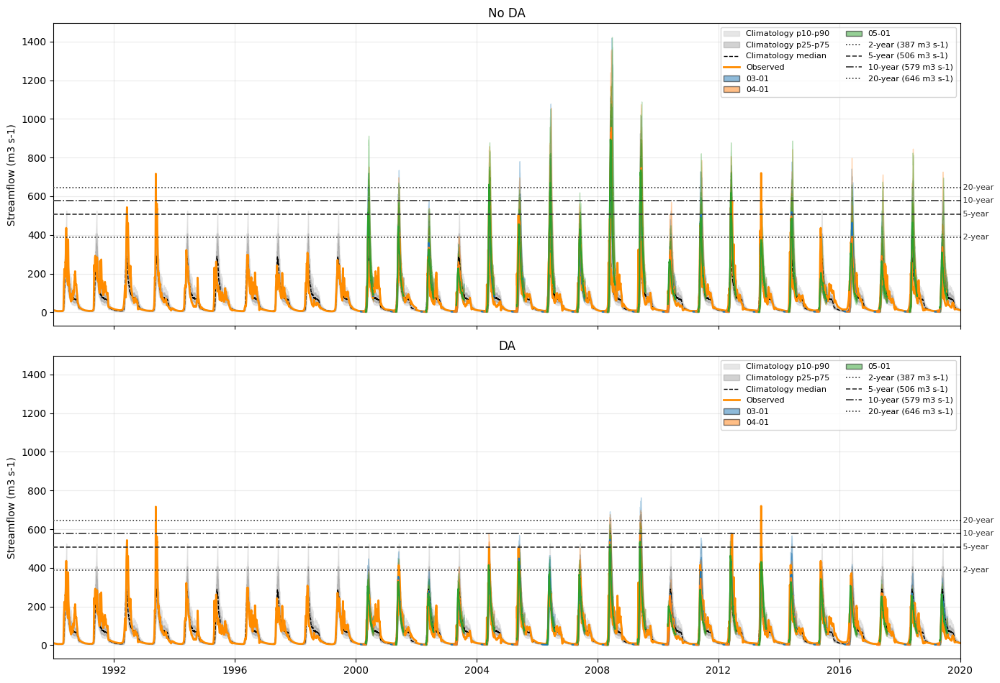

In [16]:
envelope_figure = plot_envelope_comparison(
    hindcasts,
    observations,
    plot_thresholds,
    PLOT_START,
    PLOT_END,
)


/var/folders/46/6y3tkg051374dmsgd2w6l9gw0000gn/T/ipykernel_41008/192548763.py:84: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(


60 initializations in 1990-01-01 to 2020-01-01


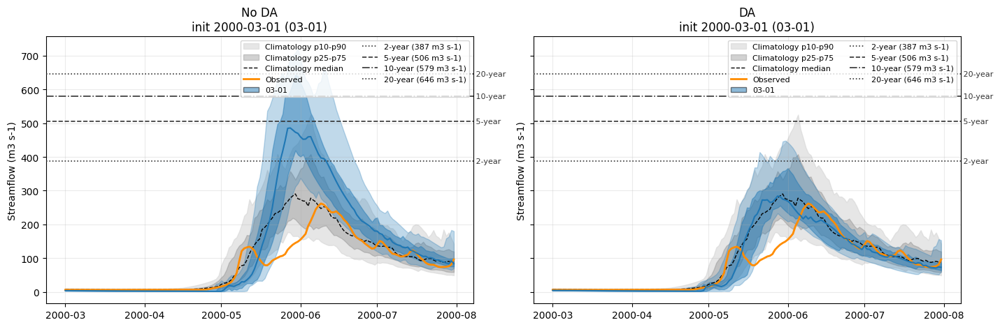

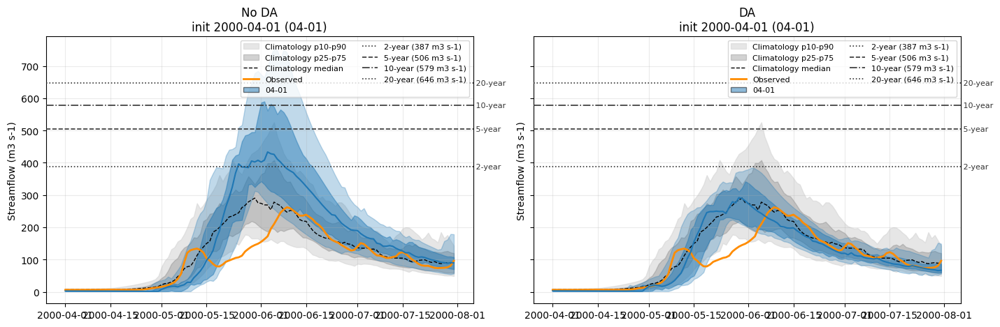

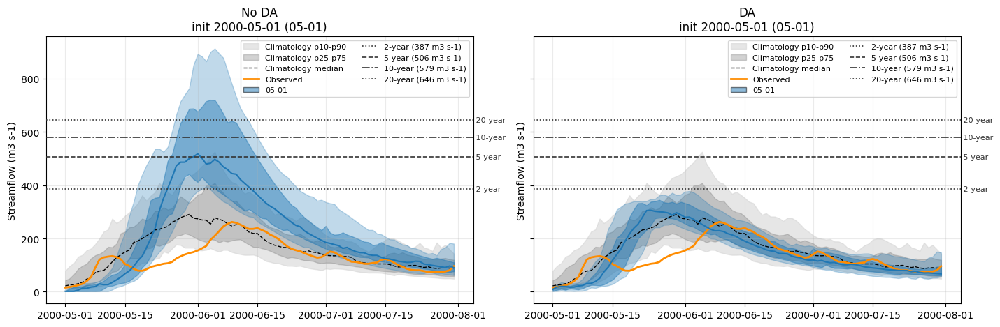

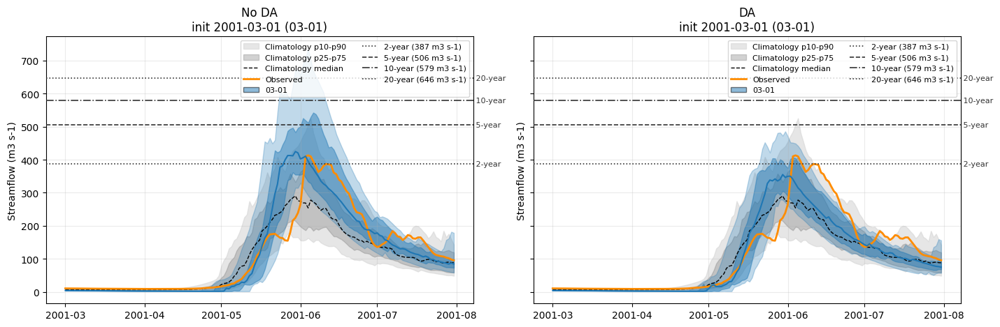

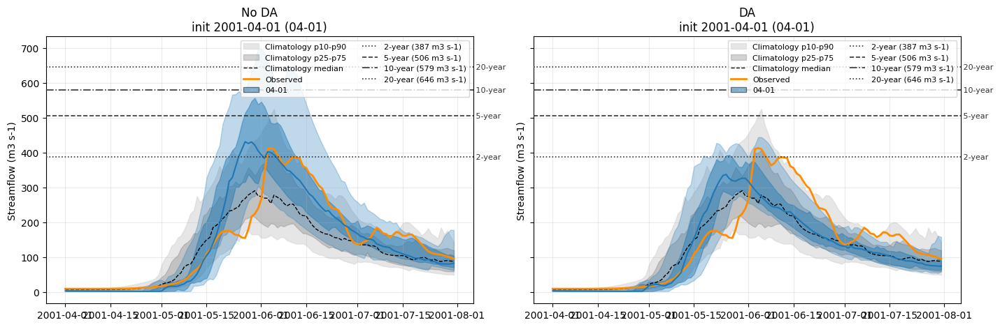

...

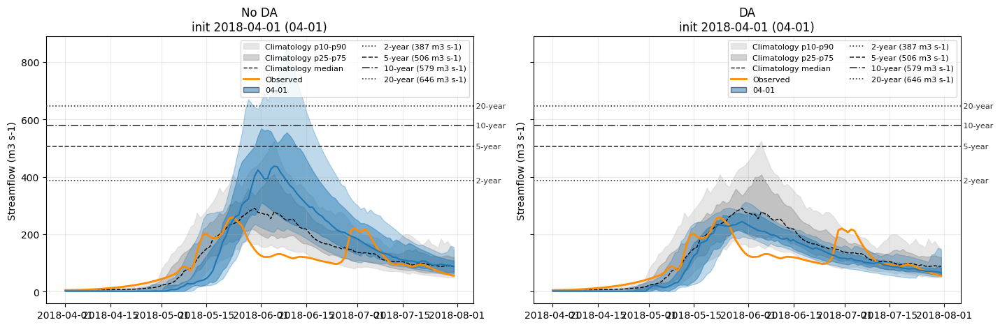

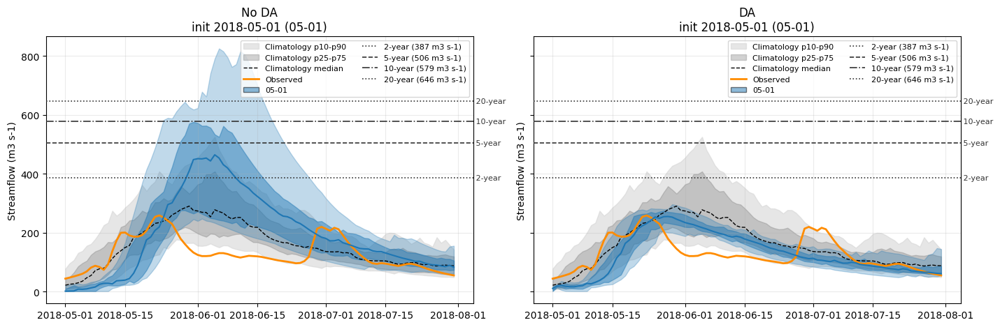

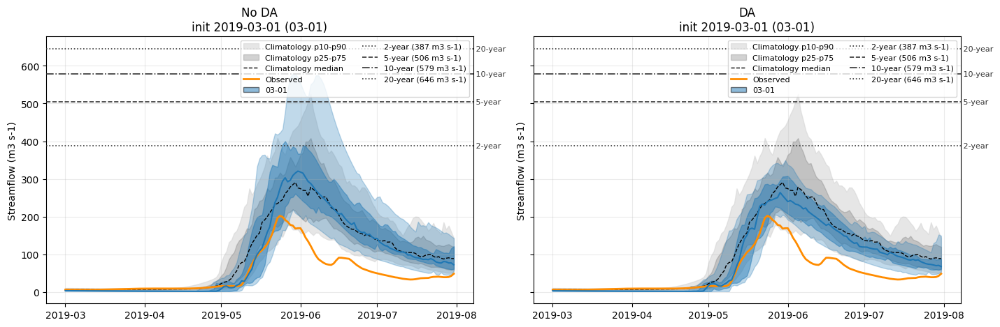

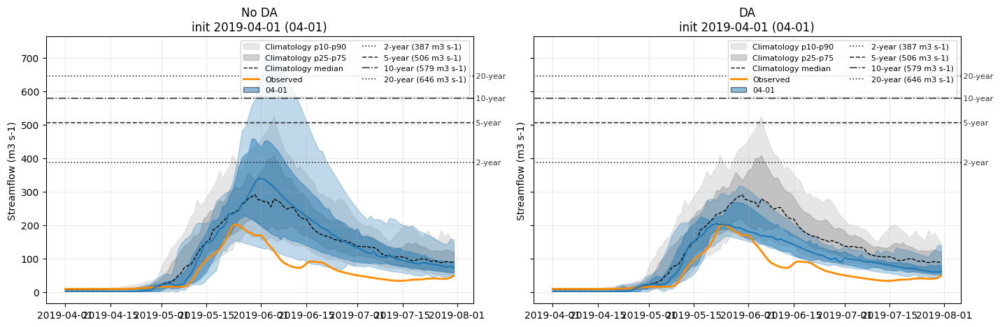

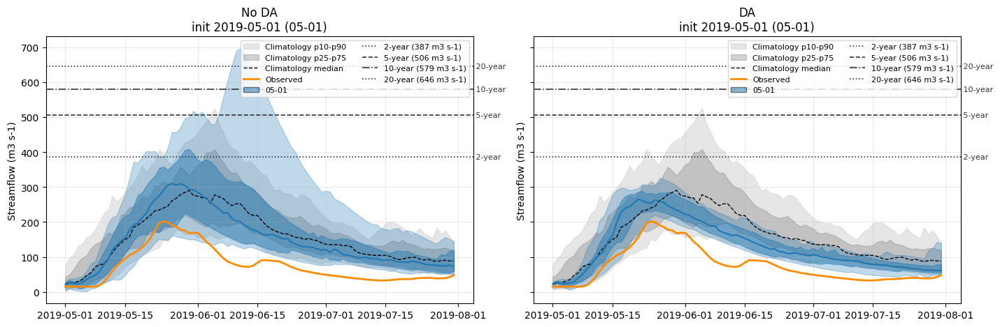

In [17]:
separate_figures = plot_separate_forecast_comparison(
    hindcasts,
    observations,
    plot_thresholds,
    PLOT_START,
    PLOT_END,
)
print(f"{len(separate_figures)} initializations in {PLOT_START} to {PLOT_END}")


## CRPS by lead

One panel per initiation month. Shading is the saved block-bootstrap interval of the mean CRPS or CRPSS at that lead. A run without those intervals is drawn as a line only. CRPSS above zero is more skillful than the observational climatology used when the scores were computed.

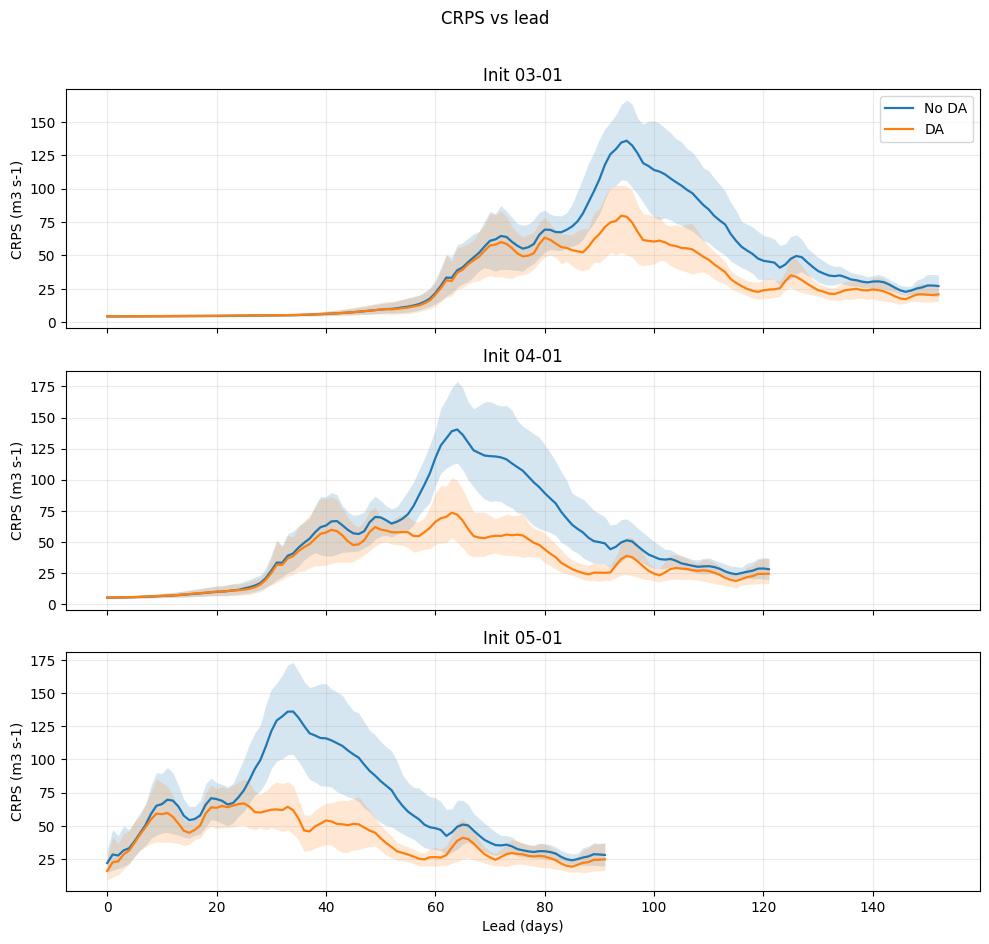

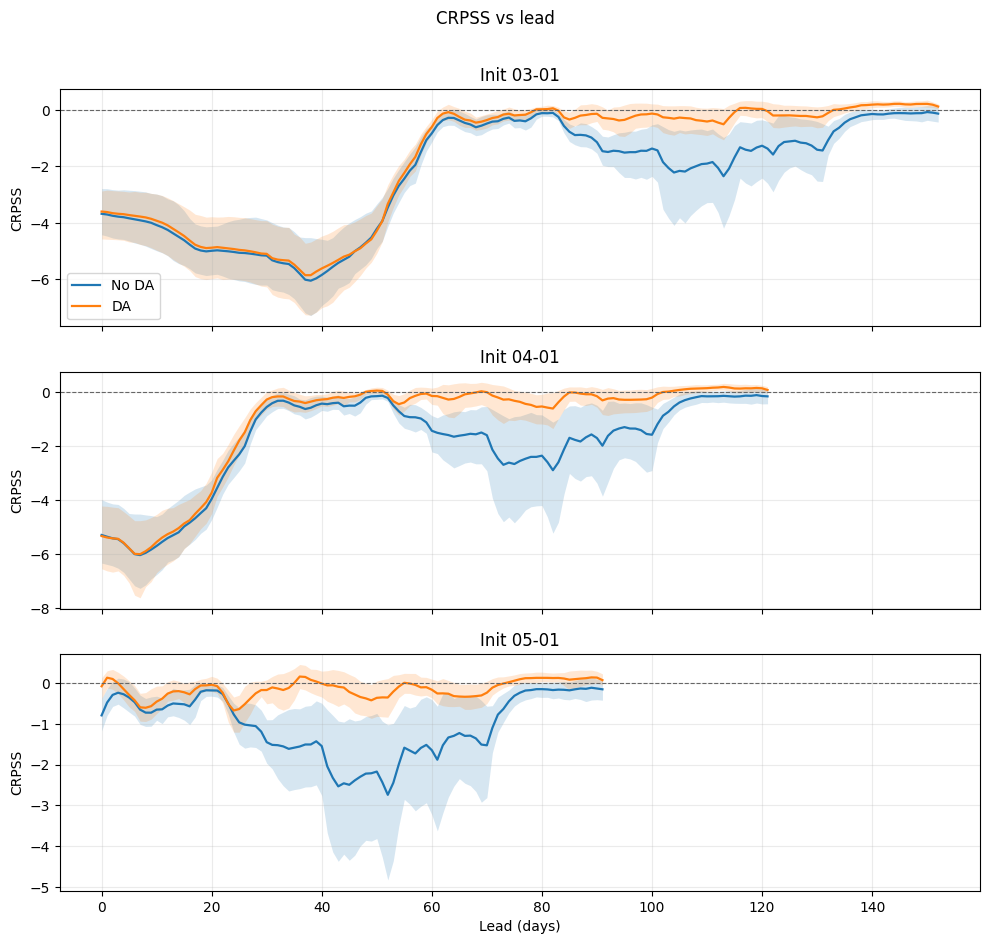

In [18]:
lead_crps = plot_score_by_lead(evaluations, skill=False)
lead_crpss = plot_score_by_lead(evaluations, skill=True)

## Initiation-month means

Error bars are the saved bootstrap interval of that month mean. Daily CRPS and peak CRPS are in streamflow units. Volume CRPS is in cubic metres. Skill scores are dimensionless.

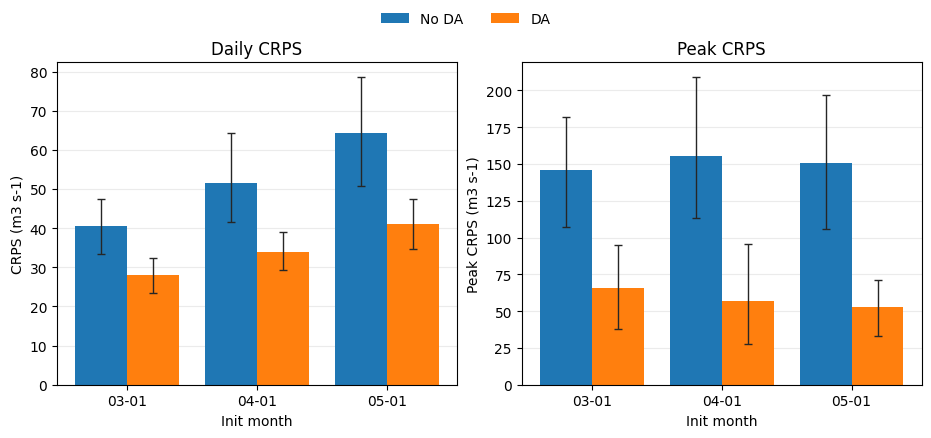

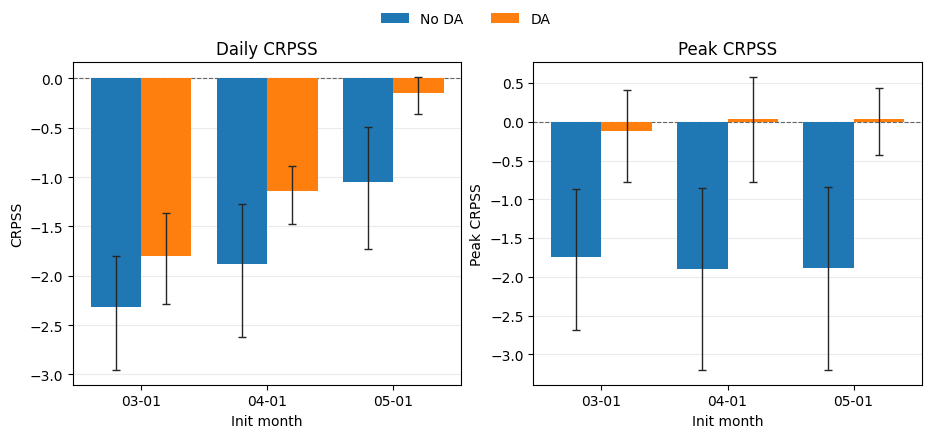

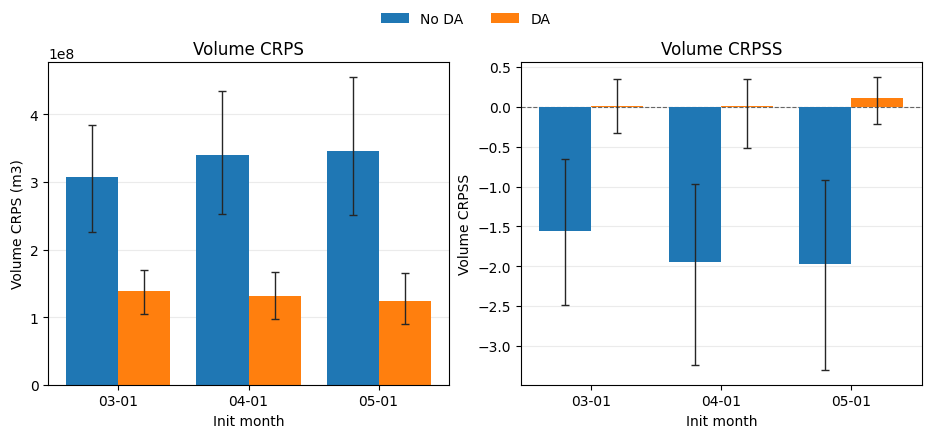

In [19]:
flow_unit = unit_of(evaluations, "peak_crps", FLOW_UNIT)
volume_unit = unit_of(evaluations, "volume_crps", VOLUME_UNIT)

crps_means = plot_month_means(
    evaluations,
    [
        ("crps_mean", f"CRPS ({flow_unit})", "Daily CRPS", False),
        ("peak_crps_mean", f"Peak CRPS ({flow_unit})", "Peak CRPS", False),
    ],
)
crpss_means = plot_month_means(
    evaluations,
    [
        ("crpss_mean", "CRPSS", "Daily CRPSS", True),
        ("peak_crpss_mean", "Peak CRPSS", "Peak CRPSS", True),
    ],
)
volume_means = None
if any("volume_crps_mean" in dataset for dataset in evaluations.values()):
    volume_means = plot_month_means(
        evaluations,
        [
            (
                "volume_crps_mean",
                f"Volume CRPS ({volume_unit})",
                "Volume CRPS",
                False,
            ),
            ("volume_crpss_mean", "Volume CRPSS", "Volume CRPSS", True),
        ],
    )

## Peak and volume scores by initialization

One point is one forecast. Panels split the initiation months so runs can be compared on a common time axis. A run that did not save volume scores is left off the volume figure.

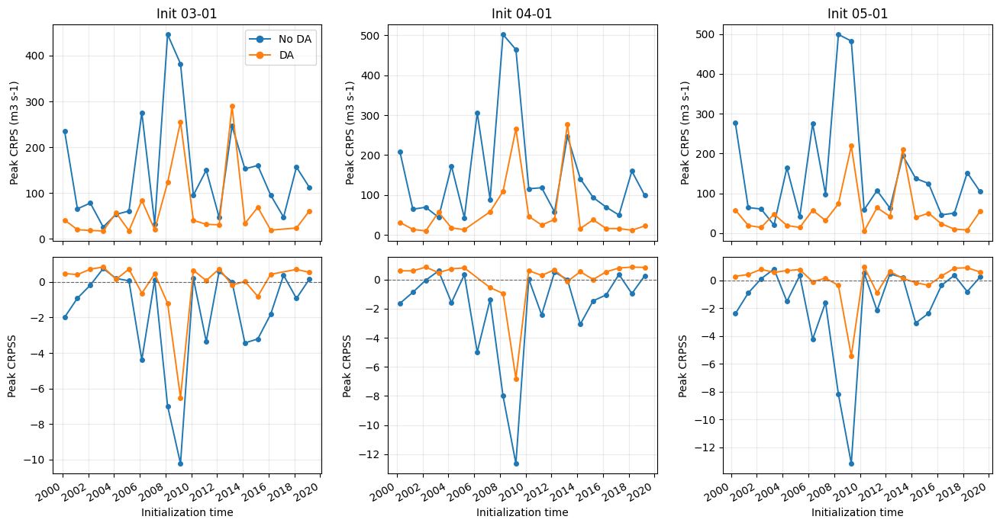

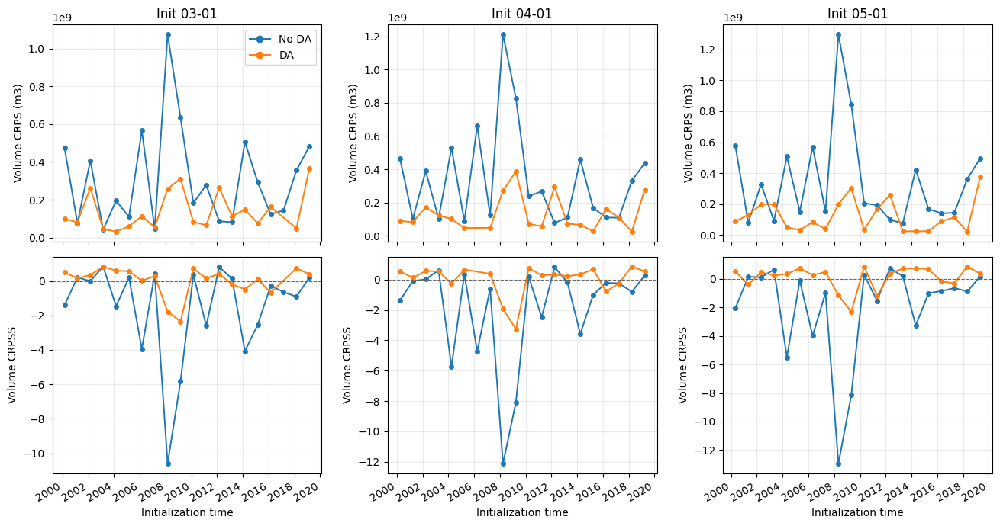

In [20]:
peak_scores = plot_horizon_scores(
    evaluations,
    "peak_crps",
    "peak_crpss",
    f"Peak CRPS ({flow_unit})",
    "Peak CRPSS",
)
volume_scores = plot_horizon_scores(
    evaluations,
    "volume_crps",
    "volume_crpss",
    f"Volume CRPS ({volume_unit})",
    "Volume CRPSS",
)

## Threshold scores

Peak-over-horizon events at the return periods stored in the metrics. The flow value under each return period is the saved `Yp` threshold, shown when every run agrees. Brier skill above zero beats the climatological event frequency used in the original score. POD and FAR use the saved probability threshold (0.5 in these files) to turn the ensemble probability into a yes/no forecast.

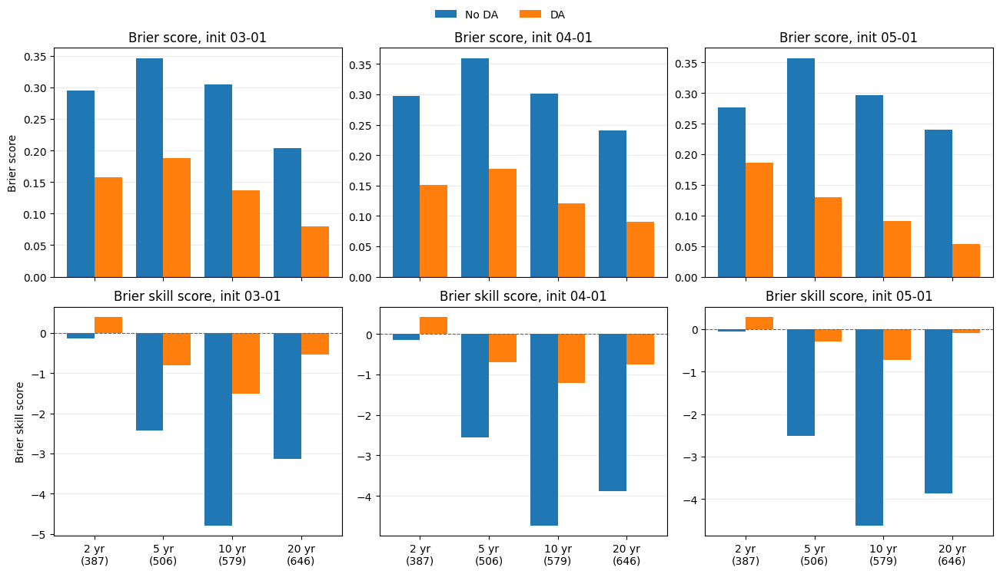

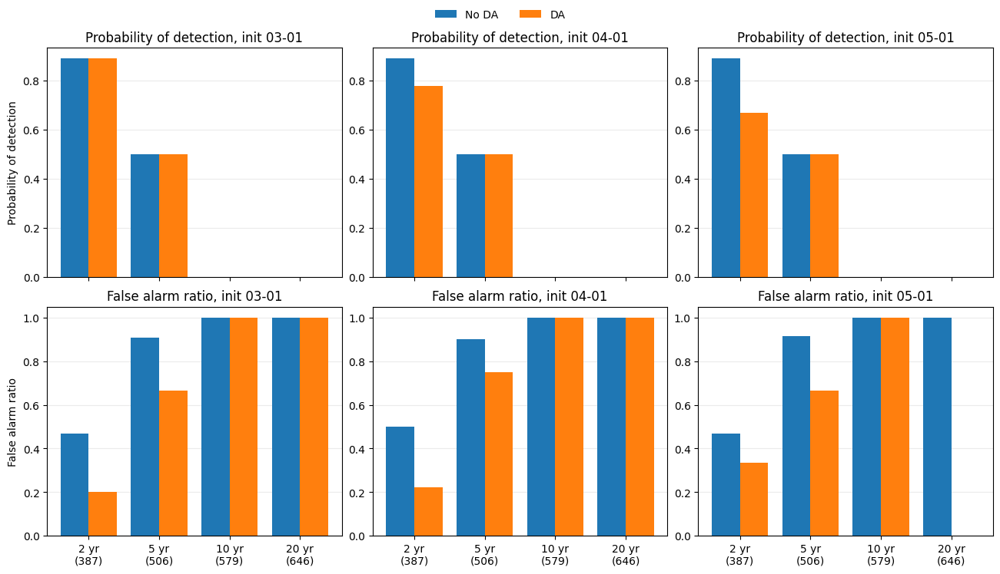

In [21]:
brier_scores = plot_threshold_bars(
    evaluations,
    ("bs", "bss"),
    ("Brier score", "Brier skill score"),
)
detection_scores = plot_threshold_bars(
    evaluations,
    ("pod", "far"),
    ("Probability of detection", "False alarm ratio"),
)

## Reliability and ROC

Both diagrams use the saved ensemble probability that the forecast peak exceeds `Yp`, and the saved indicator that the observed peak exceeded that threshold. Each panel is one initiation month and one return period. Empty reliability bins are omitted. Marker area is the number of forecasts in the bin, scaled within that panel. The dotted horizontal line is that run's observed event frequency. ROC legends include the area under the curve.

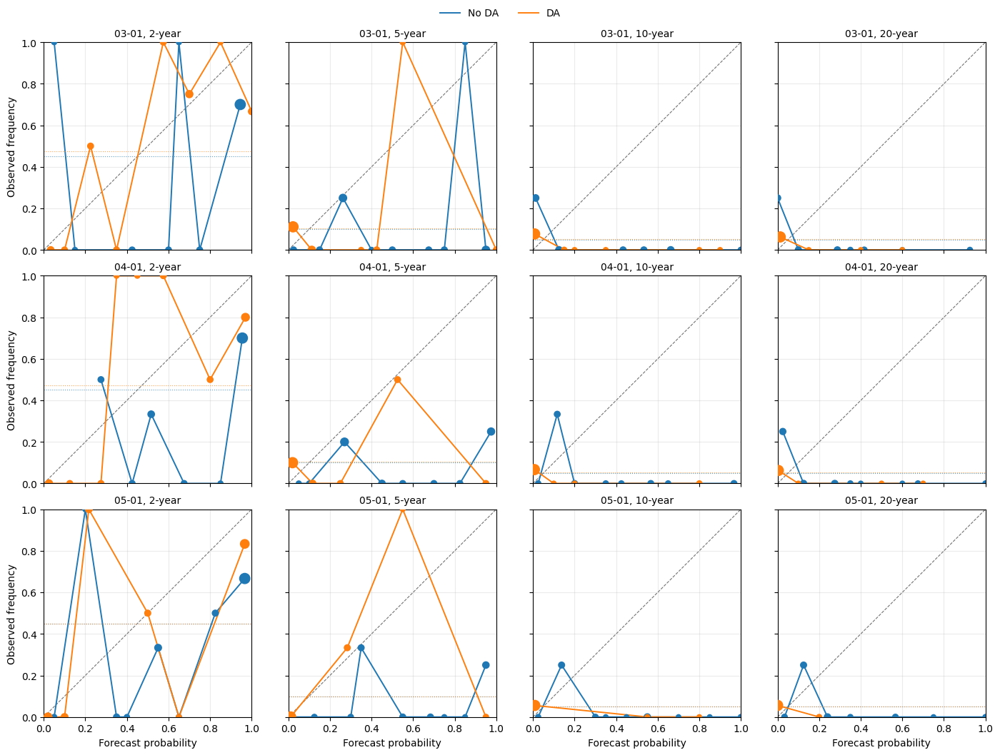

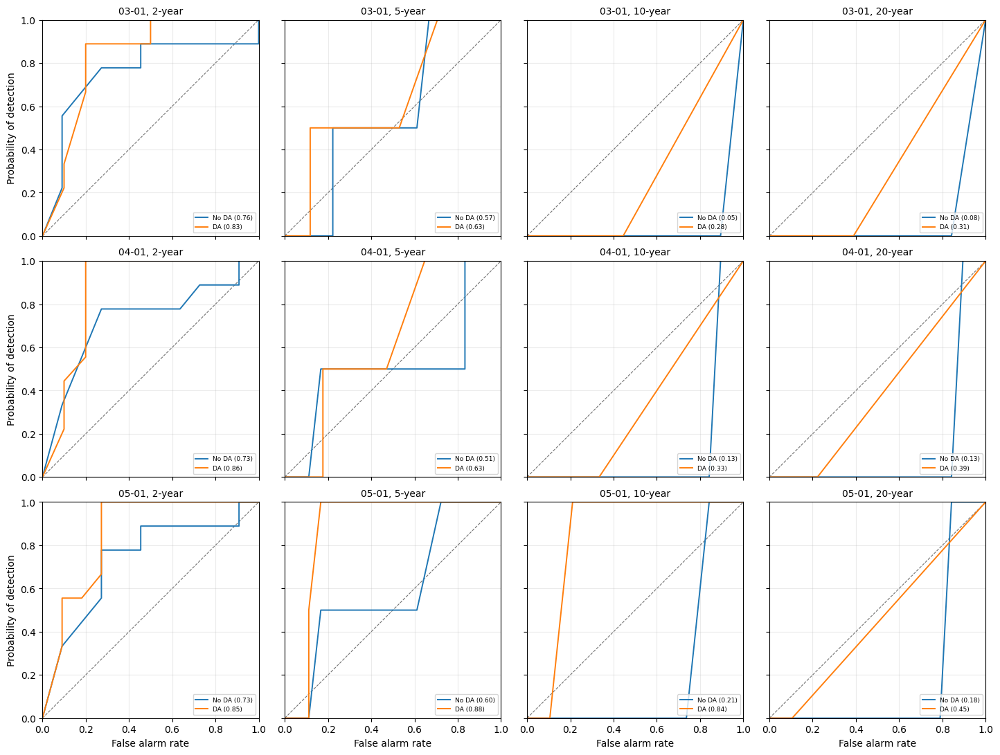

In [22]:
reliability = {
    label: reliability_diagram(
        dataset["event_probability"],
        dataset["event_observed"],
    )
    for label, dataset in evaluations.items()
    if "event_probability" in dataset and "event_observed" in dataset
}
roc = {
    label: roc_diagram(
        dataset["event_probability"],
        dataset["event_observed"],
    )
    for label, dataset in evaluations.items()
    if "event_probability" in dataset and "event_observed" in dataset
}
reliability_figure = plot_reliability(reliability)
roc_figure = plot_roc(roc)

## Rank histogram

Frequency of the observation's rank in the ensemble, by initiation month. Rank 1 is below every member. The dashed line is the uniform frequency for that run's own number of ranks, drawn in the run color. Ensemble size can differ, so the rank axes and the uniform frequencies do not have to match.

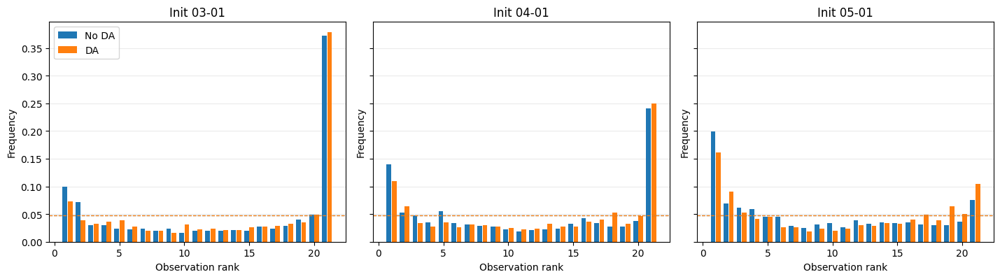

In [23]:
rank_figure = plot_rank_histograms(evaluations)